# STM/STS data-load test

Sanity check that raw Nanonis data and the sidpy datasets converted from it
are consistent, before the simulator uses them. Uses the bundled
`mexpsimu/data/stm_data/large_area/` folder (`.sxm` + `.3ds` of the same
frame) for both conversion cases:

- **combined** -- `.sxm` + `.3ds`: the bundled `large_area/sidpy/..._combined_sd.h5`;
- **`.3ds` only** -- the same folder's `.3ds` alone, converted here into a
  temporary folder (`..._3ds_sd.h5`).

Raw files are read with the SciFiReaders Nanonis readers
(`Nanonis3dsReader`, `NanonisSXMReader`; needs the gnganesh99/SciFiReaders
fork). The converted files hold two sections of NSID channels:

- `spectroscopy` -- the `.3ds` 3-D channels `(Y, X, Bias)`: `Current`,
  `LIX 1 omega`, `LIY 1 omega` (`... [bwd]` for backward sweeps, if recorded);
- `topography` -- 2-D `(Y, X)` images: the `.sxm` channels (`Z forward`,
  `Current backward`, ...) if any, plus the `.3ds` grid's own `Topography`
  (the Z-controller height at each grid pixel).

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import sidpy
import SciFiReaders as sr

sys.path.insert(0, "..")  # so `scripts` is importable from notebooks/
from scripts.combine_stm_datasets import read_nanonis_file
from mexpsimu.nsid_io import open_readonly, read_channels

warnings.filterwarnings("ignore", category=FutureWarning, module="pyNSID")

print("sidpy", sidpy.__version__)
print("SciFiReaders", sr.__version__, "from", Path(sr.__file__).parent)

DATA_DIR = Path("../mexpsimu/data/stm_data")
large = DATA_DIR / "large_area"
print("raw:", sorted(p.name for p in large.iterdir() if p.suffix in (".3ds", ".sxm")))
print("sidpy:", sorted(p.name for p in (large / "sidpy").glob("*.h5")))

sidpy 0.12.9
SciFiReaders 0.12.7 from /Users/ggn/1py_scripts/Aecroscopy_hackathon/MExpSim/mexpsimu_stm/.venv/lib/python3.11/site-packages/SciFiReaders
raw: ['EnZn2As2122.sxm', 'EuZn2As2008.3ds']
sidpy: ['EuZn2As2008_EnZn2As2122_combined_sd.h5']


## Raw files (`large_area`)

Read straight from the Nanonis files. Channel keys, quantities and units
come from the file's channel names, e.g. `LIX 1 omega (A)` -> key
`LIX 1 omega`, unit `A`, forward direction.

In [2]:
def describe(channels):
    for name, ds in channels.items():
        axes = ", ".join(f"{a.name}[{len(a.values)}] {a.units}" for a in ds._axes.values())
        print(f"  {name!r:24} shape={ds.shape}  quantity={ds.quantity!r}  units={ds.units!r}  axes=({axes})")


raw_grid = read_nanonis_file(next(large.glob("*.3ds")))
raw_scan = read_nanonis_file(next(large.glob("*.sxm")))
print(".3ds:")
describe(raw_grid)
print(".sxm:")
describe(raw_scan)

.3ds:
  'Current'                shape=(180, 180, 121)  quantity='Current'  units='A'  axes=(Y[180] nm, X[180] nm, Bias[121] V)
  'LIX 1 omega'            shape=(180, 180, 121)  quantity='LIX 1 omega'  units='A'  axes=(Y[180] nm, X[180] nm, Bias[121] V)
  'LIY 1 omega'            shape=(180, 180, 121)  quantity='LIY 1 omega'  units='A'  axes=(Y[180] nm, X[180] nm, Bias[121] V)
  'Topography'             shape=(180, 180)  quantity='Z'  units='m'  axes=(Y[180] nm, X[180] nm)
.sxm:
  'Z forward'              shape=(512, 512)  quantity='Z'  units='m'  axes=(Y[512] nm, X[512] nm)
  'Z backward'             shape=(512, 512)  quantity='Z'  units='m'  axes=(Y[512] nm, X[512] nm)
  'Current forward'        shape=(512, 512)  quantity='Current'  units='A'  axes=(Y[512] nm, X[512] nm)
  'Current backward'       shape=(512, 512)  quantity='Current'  units='A'  axes=(Y[512] nm, X[512] nm)
  'LIX_1_omega forward'    shape=(512, 512)  quantity='LIX_1_omega'  units='A'  axes=(Y[512] nm, X[512] nm)
  'L

## Converted sidpy file (`large_area/sidpy/`)

Read back strictly read-only (`mexpsimu.nsid_io`) -- `SciFiReaders.NSIDReader`
opens files in `r+` mode, which rewrites the bundled file's bytes on close.

In [3]:
def load_converted(folder):
    """(path, {section: {channel: (quantity, units, array, {axis: values})}}),
    materialized so the file can close."""
    path, = (folder / "sidpy").glob("*.h5")
    with open_readonly(path) as h5f:
        return path, {
            section: {name: (ds.quantity, ds.units, np.array(ds), {i: np.array(a.values) for i, a in ds._axes.items()})
                      for name, ds in read_channels(h5f[section]).items()}
            for section in h5f
        }


path, sections = load_converted(large)
print(path.name)
for section, channels in sections.items():
    print(f"{section}: {len(channels)} channels")
    for name, (quantity, units, arr, _) in channels.items():
        print(f"  {name!r:24} shape={arr.shape}  quantity={quantity!r}  units={units!r}")

EuZn2As2008_EnZn2As2122_combined_sd.h5
spectroscopy: 3 channels
  'Current'                shape=(180, 180, 121)  quantity='Current'  units='A'
  'LIX 1 omega'            shape=(180, 180, 121)  quantity='LIX 1 omega'  units='A'
  'LIY 1 omega'            shape=(180, 180, 121)  quantity='LIY 1 omega'  units='A'
topography: 9 channels
  'Current backward'       shape=(512, 512)  quantity='Current'  units='A'
  'Current forward'        shape=(512, 512)  quantity='Current'  units='A'
  'LIX_1_omega backward'   shape=(512, 512)  quantity='LIX_1_omega'  units='A'
  'LIX_1_omega forward'    shape=(512, 512)  quantity='LIX_1_omega'  units='A'
  'LIY_1_omega backward'   shape=(512, 512)  quantity='LIY_1_omega'  units='A'
  'LIY_1_omega forward'    shape=(512, 512)  quantity='LIY_1_omega'  units='A'
  'Topography'             shape=(180, 180)  quantity='Z'  units='m'
  'Z backward'             shape=(512, 512)  quantity='Z'  units='m'
  'Z forward'              shape=(512, 512)  quantity='Z'  un

## Converted == raw

Every channel of the converted file must match the raw reader output
exactly: same keys, arrays, quantity, units and axis values.

In [4]:
def compare(raw, sections):
    saved = {name: ch for channels in sections.values() for name, ch in channels.items()}
    problems = []
    if set(raw) != set(saved):
        problems.append(f"channel sets differ: {sorted(set(raw) ^ set(saved))}")
    for name in set(raw) & set(saved):
        quantity, units, arr, axes = saved[name]
        ds = raw[name]
        if not np.array_equal(np.array(ds), arr, equal_nan=True):
            problems.append(f"{name}: data")
        if (ds.quantity, ds.units) != (quantity, units):
            problems.append(f"{name}: quantity/units")
        if any(not np.allclose(np.array(a.values), axes[i]) for i, a in ds._axes.items()):
            problems.append(f"{name}: axes")
    return problems


problems = compare({**raw_scan, **raw_grid}, sections)
print(f"combined: {len(raw_scan) + len(raw_grid)} channels, {problems or 'OK'}")
assert not problems

combined: 12 channels, OK


## Topography: `.sxm` image vs `.3ds` grid `Topography` (`large_area`)

Both cover the same frame (same centre, size and angle), so the grid's
Z-controller map should show the same features as the `.sxm` scan, at the
coarser grid resolution. Both are plotted with row 0 at the bottom
(`origin="lower"`).

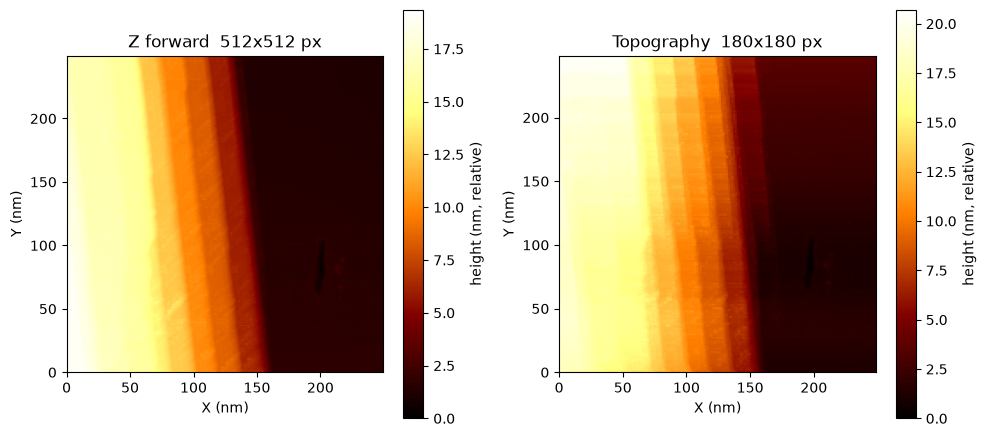

correlation .sxm Z forward vs .3ds Topography: 0.977


In [5]:
def extent(axes):
    y, x = axes[0], axes[1]  # (Y, X) axis order
    return [x.min(), x.max(), y.min(), y.max()]


topo = sections["topography"]
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, name in zip(axs, ["Z forward", "Topography"]):
    _, _, z, axes = topo[name]
    im = ax.imshow((z - np.nanmin(z)) * 1e9, origin="lower", extent=extent(axes), cmap="afmhot")
    ax.set_title(f"{name}  {z.shape[1]}x{z.shape[0]} px")
    ax.set_xlabel("X (nm)")
    ax.set_ylabel("Y (nm)")
    fig.colorbar(im, ax=ax, label="height (nm, relative)")
fig.tight_layout()
plt.show()

# Downsample the .sxm image onto the grid and correlate, as a numeric check
# that the two maps line up (same orientation, same frame).
_, _, z_sxm, ax_sxm = topo["Z forward"]
_, _, z_grid, ax_grid = topo["Topography"]
rows = np.searchsorted(ax_sxm[0], ax_grid[0]).clip(0, z_sxm.shape[0] - 1)
cols = np.searchsorted(ax_sxm[1], ax_grid[1]).clip(0, z_sxm.shape[1] - 1)
z_sxm_on_grid = z_sxm[np.ix_(rows, cols)]
ok = np.isfinite(z_grid) & np.isfinite(z_sxm_on_grid)
print(f"correlation .sxm Z forward vs .3ds Topography: {np.corrcoef(z_sxm_on_grid[ok], z_grid[ok])[0, 1]:.3f}")

## Grid spectroscopy (`large_area`)

`LIX 1 omega` is the lock-in X output, proportional to `dI/dV`; it should
track a numerically differentiated `Current` at the same pixel.

bias sweep: -1.50 V -> 2.50 V, 121 points
Current cube: (180, 180, 121), LIX 1 omega cube: (180, 180, 121)


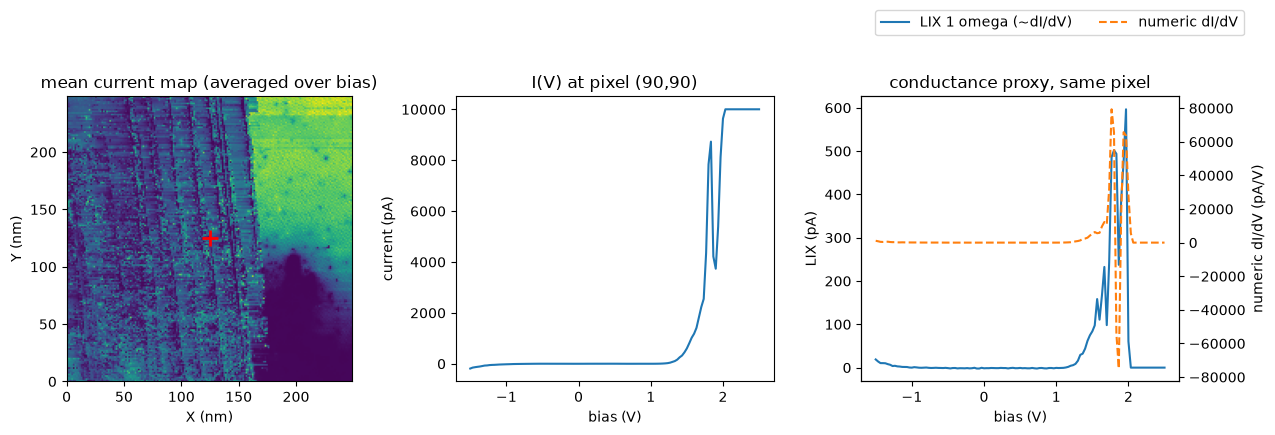

correlation LIX 1 omega vs numeric dI/dV (whole cube): 0.740


In [6]:
spec = sections["spectroscopy"]
_, _, current, axes = spec["Current"]
_, _, lix, _ = spec["LIX 1 omega"]
bias = axes[2]
print(f"bias sweep: {bias.min():.2f} V -> {bias.max():.2f} V, {len(bias)} points")
print(f"Current cube: {current.shape}, LIX 1 omega cube: {lix.shape}")

row, col = current.shape[0] // 2, current.shape[1] // 2
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))

axs[0].imshow(current.mean(axis=2), origin="lower", extent=extent(axes), cmap="viridis")
axs[0].plot(axes[1][col], axes[0][row], "r+", markersize=12, markeredgewidth=2)
axs[0].set_title("mean current map (averaged over bias)")
axs[0].set_xlabel("X (nm)")
axs[0].set_ylabel("Y (nm)")

axs[1].plot(bias, current[row, col] * 1e12)
axs[1].set_xlabel("bias (V)")
axs[1].set_ylabel("current (pA)")
axs[1].set_title(f"I(V) at pixel ({row},{col})")

axs[2].plot(bias, lix[row, col] * 1e12, label="LIX 1 omega (~dI/dV)")
ax2 = axs[2].twinx()
ax2.plot(bias, np.gradient(current[row, col], bias) * 1e12, "--", color="tab:orange", label="numeric dI/dV")
axs[2].set_xlabel("bias (V)")
axs[2].set_ylabel("LIX (pA)")
ax2.set_ylabel("numeric dI/dV (pA/V)")
axs[2].set_title("conductance proxy, same pixel")
fig.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.83, 1.15))
fig.tight_layout()
plt.show()

didv = np.gradient(current, bias, axis=2)
ok = np.isfinite(didv) & np.isfinite(lix)
print(f"correlation LIX 1 omega vs numeric dI/dV (whole cube): {np.corrcoef(lix[ok], didv[ok])[0, 1]:.3f}")

## `.3ds` only

When a folder has no `.sxm`, `convert_nanonis_folder` writes a `.3ds`-only
file: the `spectroscopy` section plus the grid `Topography` as the only
topography channel. Exercised here on `large_area`'s `.3ds` alone, linked
into a temporary folder so nothing is written next to the bundled data.

In [7]:
import tempfile

from scripts.combine_stm_datasets import convert_nanonis_folder

tmp_folder = Path(tempfile.mkdtemp()) / "large_area_3ds_only"
tmp_folder.mkdir()
grid_file = next(large.glob("*.3ds"))
(tmp_folder / grid_file.name).symlink_to(grid_file.resolve())

convert_nanonis_folder(tmp_folder)
path_3ds, sections_3ds = load_converted(tmp_folder)
print({s: list(c) for s, c in sections_3ds.items()})

problems = compare(raw_grid, sections_3ds)
print(f".3ds only: {len(raw_grid)} channels, {problems or 'OK'}")
assert not problems

EuZn2As2008.3ds -> /var/folders/bf/82yswzpd5yx9l9zp3nqyqs3r0000gn/T/tmp3yp00mjo/large_area_3ds_only/sidpy/EuZn2As2008_3ds_sd.h5 (1 topography, 3 spectroscopy channels)
{'spectroscopy': ['Current', 'LIX 1 omega', 'LIY 1 omega'], 'topography': ['Topography']}
.3ds only: 4 channels, OK


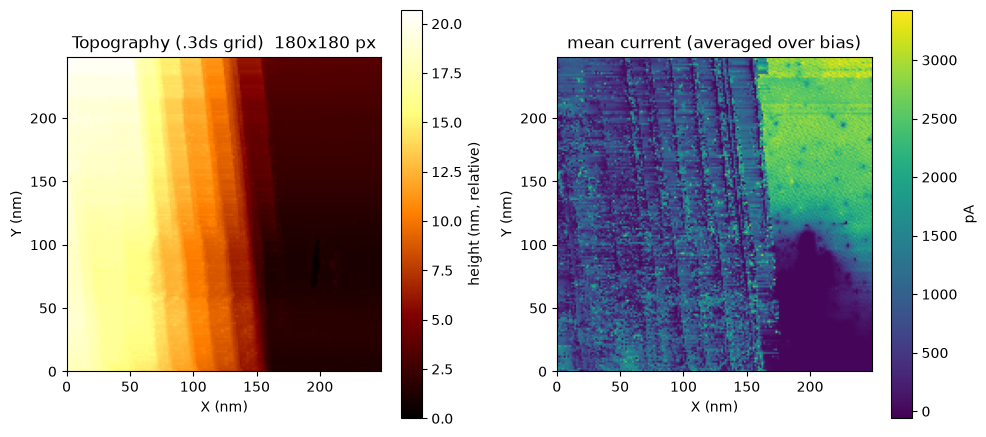

In [8]:
_, _, z, axes = sections_3ds["topography"]["Topography"]
_, _, cur, _ = sections_3ds["spectroscopy"]["Current"]

fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
im = axs[0].imshow((z - np.nanmin(z)) * 1e9, origin="lower", extent=extent(axes), cmap="afmhot")
axs[0].set_title(f"Topography (.3ds grid)  {z.shape[1]}x{z.shape[0]} px")
fig.colorbar(im, ax=axs[0], label="height (nm, relative)")
im = axs[1].imshow(cur.mean(axis=2) * 1e12, origin="lower", extent=extent(axes), cmap="viridis")
axs[1].set_title("mean current (averaged over bias)")
fig.colorbar(im, ax=axs[1], label="pA")
for ax in axs:
    ax.set_xlabel("X (nm)")
    ax.set_ylabel("Y (nm)")
fig.tight_layout()
plt.show()

## Result

- Both the combined and the `.3ds`-only conversions match the raw Nanonis
  readers exactly (channels, arrays, quantities, units, axes).
- The `.3ds` grid `Topography` lines up with the `.sxm` `Z forward` image of
  the same frame, and `LIX 1 omega` tracks the numeric `dI/dV` of `Current`.
- `.3ds`-only data still provides a real topography image.

## Converting new data

Put one `.3ds` (and optionally one `.sxm` of the same frame) in a new folder
and convert it -- the cell below is commented out since the path is a
placeholder. `python scripts/combine_stm_datasets.py` converts every folder
under `stm_data/` at once.

In [9]:
# from scripts.combine_stm_datasets import convert_nanonis_folder
#
# convert_nanonis_folder(DATA_DIR / "my_new_folder")              # -> my_new_folder/sidpy/<...>_sd.h5
# convert_nanonis_folder(DATA_DIR / "my_new_folder", overwrite=True)  # re-convert
#
# # combine_sidpy_datasets() still merges existing pyNSID .h5 files into named sections:
# # from scripts.combine_stm_datasets import combine_sidpy_datasets
# # combine_sidpy_datasets(sources={"topography": "...h5", "spectroscopy": "...h5"}, output_path="...h5")